In [1]:
!pip install pandas numpy matplotlib scipy scikit-learn sdv  
import re, random
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
np.random.seed(SEED)
rng = random.Random(SEED)
pd.set_option("display.max_colwidth", 120)


[notice] A new release of pip available: 22.2.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [17]:
import platform, os
print(platform.platform(), "| Python", platform.python_version(), "| CPUs:", os.cpu_count())
!lscpu | head -20

Linux-5.14.0-427.144.1.el9_4.x86_64-x86_64-with-glibc2.34 | Python 3.9.16 | CPUs: 48
Architecture:                         x86_64
CPU op-mode(s):                       32-bit, 64-bit
Address sizes:                        46 bits physical, 57 bits virtual
Byte Order:                           Little Endian
CPU(s):                               48
On-line CPU(s) list:                  0-47
Vendor ID:                            GenuineIntel
Model name:                           INTEL(R) XEON(R) GOLD 6542Y
CPU family:                           6
Model:                                207
Thread(s) per core:                   2
Core(s) per socket:                   24
Socket(s):                            1
Stepping:                             2
BogoMIPS:                             5800.00
Flags:                                fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush dts acpi mmx fxsr sse sse2 ss ht tm pbe syscall nx pdpe1gb rdtscp lm constant_tsc art

In [4]:
DATA_PATH = "Synthetic Data Generator/Final_Dataset.csv"  
df_real = pd.read_csv(DATA_PATH)
df_real = df_real.loc[:, ~df_real.columns.str.startswith("Unnamed")]   # drop saved index columns
df_real.head()

,Fillings,Fraud
0,nanitem 14 exhibits financial statements reports form 10k index exhibits following documents filed part report 1 see...,yes
1,item 14 principal accounting fees services material included 2014 proxy statement headings audit fees nonaudit fees ...,no
2,item 14 exhibits financial statements schedules reports form 8k afinancial statements schedules 1 financial statemen...,yes
3,item 14 exhibits financial statement schedules reports form 8k 1 financial statements presentation financial stateme...,yes
4,item 14 exhibits financial statement schedules reports form 8k exhibits 21 restated agreement plan merger dated nove...,no


In [5]:
#STEP 1: Schema, stats, nulls

print(df_real.shape)
df_real.info()
display(df_real.describe(include="all").T)
display(df_real.isna().sum().to_frame("nulls"))

TEXT_COLS, CAT_COLS, NUM_COLS = [], [], []
for c in df_real.columns:
    s = df_real[c]
    if s.dtype == object and s.dropna().astype(str).str.len().mean() > 200:
        TEXT_COLS.append(c)
    elif s.dtype == object or s.nunique() <= 10:
        CAT_COLS.append(c)
    else:
        NUM_COLS.append(c)

label_guess = [c for c in CAT_COLS if c.lower() in ("fraud", "label", "class", "target", "is_fraud")]
LABEL_COL = label_guess[0] if label_guess else (CAT_COLS[-1] if CAT_COLS else None)
print("Text:", TEXT_COLS, "| Categorical:", CAT_COLS, "| Numeric:", NUM_COLS, "| Label:", LABEL_COL)

(170, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Fillings  170 non-null    object
 1   Fraud     170 non-null    object
dtypes: object(2)
memory usage: 2.8+ KB


,count,unique,top,freq
Fillings,170,170,nanitem 14 exhibits financial statements reports form 10k index exhibits following documents filed part report 1 see...,1
Fraud,170,2,yes,85


,nulls
Fillings,0
Fraud,0


Text: ['Fillings'] | Categorical: ['Fraud'] | Numeric: [] | Label: Fraud


In [6]:
#STEP 1: Category frequencies

for c in CAT_COLS:
    print(f"\n--- {c} ---")
    display(df_real[c].value_counts(normalize=True, dropna=False).to_frame("freq"))


--- Fraud ---


,freq
Fraud,
yes,0.5
no,0.5


In [7]:
#STEP 1: Turning text into numbers

RISK_TERMS = ["restatement", "restated", "impairment", "litigation", "material weakness",
              "going concern", "investigation", "sec", "loss", "revenue", "related party"]

def text_features(s):
    s = "" if pd.isna(s) else str(s)
    low = s.lower()
    words = re.findall(r"[A-Za-z']+", s)
    n = max(len(words), 1)
    feats = {
        "char_len": len(s),
        "word_count": len(words),
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0.0,
        "digit_ratio": sum(ch.isdigit() for ch in s) / max(len(s), 1),
        "dollar_per_1k_words": s.count("$") / n * 1000,
        "pct_per_1k_words": s.count("%") / n * 1000,
    }
    for t in RISK_TERMS:
        feats[f"kw_{t.replace(' ', '_')}_per_1k"] = low.count(t) / n * 1000
    return feats

def profile(df):
    out = []
    for tc in TEXT_COLS:
        f = pd.DataFrame([text_features(x) for x in df[tc]]).add_prefix(f"{tc}__")
        out.append(f)
    prof = pd.concat(out, axis=1) if out else pd.DataFrame(index=df.index)
    if LABEL_COL:
        prof[LABEL_COL] = df[LABEL_COL].values
    return prof

prof_real = profile(df_real)
display(prof_real.groupby(LABEL_COL).mean().T if LABEL_COL else prof_real.describe().T)

Fraud,no,yes
Fillings__char_len,497178.870588,2.058520e+06
Fillings__word_count,57030.952941,2.352668e+05
Fillings__avg_word_len,7.102796,7.300551e+00
Fillings__digit_ratio,0.047342,3.977398e-02
Fillings__dollar_per_1k_words,0.000000,0.000000e+00
Fillings__pct_per_1k_words,0.000000,0.000000e+00
Fillings__kw_restatement_per_1k,0.023269,5.958670e-02
Fillings__kw_restated_per_1k,0.275436,4.287680e-01
Fillings__kw_impairment_per_1k,0.570121,1.931950e+00
Fillings__kw_litigation_per_1k,0.350108,4.696853e-01


In [8]:
# Step 2, Option A: NumPy/Pandas generator (label-aware Markov text)

N_ROWS = 1000          # rows to generate
MARKOV_ORDER = 2       # higher = more fluent text, but copies more of the real text
TRAIN_TOKENS_PER_DOC = 20000   # limit memory/time
MAX_GEN_WORDS = 3000   # set None to match real length fully (slower)

def tokenize(s):
    return re.findall(r"\S+", str(s))

def build_chain(texts, k):
    chain, starts = defaultdict(list), []
    for t in texts:
        toks = tokenize(t)[:TRAIN_TOKENS_PER_DOC]
        if len(toks) <= k:
            continue
        starts.append(tuple(toks[:k]))
        for i in range(len(toks) - k):
            chain[tuple(toks[i:i + k])].append(toks[i + k])
    return chain, starts

def gen_text(chain, starts, n_words, k):
    state = rng.choice(starts)
    out = list(state)
    while len(out) < n_words:
        nxt = chain.get(state)
        if not nxt:                       # reached a dead end: start again from a random start
            state = rng.choice(starts); out.extend(state); continue
        w = rng.choice(nxt); out.append(w)
        state = tuple(out[-k:])
    return " ".join(out[:n_words])

# 1) Labels / categorical columns: sample from the real frequencies
syn = {}
if LABEL_COL:
    p = df_real[LABEL_COL].value_counts(normalize=True, dropna=False)
    syn[LABEL_COL] = np.random.choice(p.index.to_numpy(), size=N_ROWS, p=p.values)
for c in [c for c in CAT_COLS if c != LABEL_COL]:
    p = df_real[c].value_counts(normalize=True, dropna=False)
    syn[c] = np.random.choice(p.index.to_numpy(), size=N_ROWS, p=p.values)

# 2) Numeric columns: log-normal if all values >= 0 and skewed, else normal; clip to the real min/max
for c in NUM_COLS:
    x = df_real[c].dropna().astype(float)
    if (x >= 0).all() and abs(stats.skew(x)) > 1:
        v = np.expm1(np.random.normal(np.log1p(x).mean(), np.log1p(x).std(), N_ROWS))
    else:
        v = np.random.normal(x.mean(), x.std(), N_ROWS)
    v = np.clip(v, x.min(), x.max())
    if pd.api.types.is_integer_dtype(df_real[c]):
        v = np.round(v).astype(int)
    syn[c] = v

df_syn = pd.DataFrame(syn)

# 3) Text columns: one Markov chain per label, length drawn from that label's real word counts
for tc in TEXT_COLS:
    texts_out = np.empty(N_ROWS, dtype=object)
    groups = df_real.groupby(LABEL_COL) if LABEL_COL else [(None, df_real)]
    for lab, g in groups:
        chain, starts = build_chain(g[tc].dropna(), MARKOV_ORDER)
        lens = g[tc].dropna().map(lambda s: len(tokenize(s))).to_numpy()
        idx = np.where(df_syn[LABEL_COL].to_numpy() == lab)[0] if LABEL_COL else np.arange(N_ROWS)
        for i in idx:
            n = int(np.random.choice(lens))
            n = min(n, MAX_GEN_WORDS) if MAX_GEN_WORDS else n
            texts_out[i] = gen_text(chain, starts, max(n, MARKOV_ORDER + 1), MARKOV_ORDER)
    df_syn[tc] = texts_out

# 4) Keep the real null rate in each column (messy edge cases)
for c in df_real.columns:
    rate = df_real[c].isna().mean()
    if rate > 0:
        df_syn.loc[np.random.rand(N_ROWS) < rate, c] = np.nan

df_syn = df_syn[df_real.columns]
df_syn.head()

,Fillings,Fraud
0,item 14 incorporated herein reference exhibits companys form 10k offbalance sheet arrangements 1997 entered offbalan...,yes
1,item 14 principal accounting fees services may include audit services rendered kenne ruan outside fees disclosed “au...,no
2,item 14 principal accountant fees services audit fees operating results following supplemental schedule report conso...,no
3,item 14 principal accountant fees services principal independent accountant required provide detailed backup documen...,no
4,item 14 exhibits financial statements regarding expectations future taxable income years ended december 31 2018 comp...,yes


In [19]:
# # Step 2, Option B (optional): SDV on the text-feature table

# try:
#     from sdv.single_table import GaussianCopulaSynthesizer
#     try:
#         from sdv.metadata import Metadata
#         md = Metadata.detect_from_dataframe(prof_real)
#     except ImportError:
#         from sdv.metadata import SingleTableMetadata
#         md = SingleTableMetadata(); md.detect_from_dataframe(prof_real)
#     sdv_model = GaussianCopulaSynthesizer(md, enforce_min_max_values=True)
#     sdv_model.fit(prof_real)
#     prof_sdv = sdv_model.sample(N_ROWS)
#     from sdv.evaluation.single_table import evaluate_quality
#     evaluate_quality(prof_real, prof_sdv, md)
# except ImportError:
#     print("SDV not installed; skipping. Run: pip install sdv")


In [10]:
# Step 3, Validation: compare distributions side by side

prof_syn = profile(df_syn)
feat_cols = [c for c in prof_real.columns if c != LABEL_COL]

side = pd.concat({"real": prof_real[feat_cols].describe().T[["mean", "std", "min", "max"]],
                  "synthetic": prof_syn[feat_cols].describe().T[["mean", "std", "min", "max"]]}, axis=1)
side["KS_stat"] = [stats.ks_2samp(prof_real[c].dropna(), prof_syn[c].dropna()).statistic for c in feat_cols]
display(side.round(3))

if LABEL_COL:
    display(pd.concat({"real": df_real[LABEL_COL].value_counts(normalize=True),
                       "synthetic": df_syn[LABEL_COL].value_counts(normalize=True)}, axis=1))
for c in NUM_COLS:
    display(pd.concat({"real": df_real[c].describe(), "synthetic": df_syn[c].describe()}, axis=1))

real                         \
                                              mean          std       min   
Fillings__char_len                     1277849.282  1406959.053  1626.000   
Fillings__word_count                    146148.900   161295.759   179.000   
Fillings__avg_word_len                       7.202        0.262     5.408   
Fillings__digit_ratio                        0.044        0.020     0.017   
Fillings__dollar_per_1k_words                0.000        0.000     0.000   
Fillings__pct_per_1k_words                   0.000        0.000     0.000   
Fillings__kw_restatement_per_1k              0.041        0.083     0.000   
Fillings__kw_restated_per_1k                 0.352        0.463     0.000   
Fillings__kw_impairment_per_1k               1.251        1.150     0.000   
Fillings__kw_litigation_per_1k               0.410        0.598     0.000   
Fillings__kw_material_weakness_per_1k        0.045        0.063     0.000   
Fillings__kw_going_concern_per_1k            0.146        0.534     0.000   
Fillings__kw_investigation_per_1k            0.182        0.279     0.000   
Fillings__kw_sec_per_1k                      7.870        7.981     0.999   
Fillings__kw_loss_per_1k                     3.165        2.427     0.000   
Fillings__kw_revenue_per_1k                  3.429        3.243     0.000   
Fillings__kw_related_party_per_1k            0.119        0.284     0.000   

                                                    synthetic            \
                                               max       mean       std   
Fillings__char_len                     5708964.000  21224.676  5834.306   
Fillings__word_count                    657555.000   2419.178   664.469   
Fillings__avg_word_len                       7.641      7.211     0.089   
Fillings__digit_ratio                        0.259      0.049     0.007   
Fillings__dollar_per_1k_words                0.000      0.000     0.000   
Fillings__pct_per_1k_words                   0.000      0.000     0.000   
Fillings__kw_restatement_per_1k              0.530      0.043     0.129   
Fillings__kw_restated_per_1k                 2.618      0.714     0.662   
Fillings__kw_impairment_per_1k               6.774      0.980     0.835   
Fillings__kw_litigation_per_1k               3.351      0.343     0.451   
Fillings__kw_material_weakness_per_1k        0.353      0.031     0.166   
Fillings__kw_going_concern_per_1k            3.955      0.136     0.356   
Fillings__kw_investigation_per_1k            1.362      0.088     0.224   
Fillings__kw_sec_per_1k                     42.566      6.011     2.188   
Fillings__kw_loss_per_1k                    21.950      3.296     1.734   
Fillings__kw_revenue_per_1k                 13.910      4.090     1.799   
Fillings__kw_related_party_per_1k            2.997      0.086     0.187   

                                                           KS_stat  
                                            min        max          
Fillings__char_len                     1696.000  24132.000   0.847  
Fillings__word_count                    198.000   2762.000   0.847  
Fillings__avg_word_len                    6.557      7.593   0.268  
Fillings__digit_ratio                     0.023      0.114   0.468  
Fillings__dollar_per_1k_words             0.000      0.000   0.000  
Fillings__pct_per_1k_words                0.000      0.000   0.000  
Fillings__kw_restatement_per_1k           0.000      1.136   0.388  
Fillings__kw_restated_per_1k              0.000      3.823   0.438  
Fillings__kw_impairment_per_1k            0.000      8.299   0.230  
Fillings__kw_litigation_per_1k            0.000      3.311   0.233  
Fillings__kw_material_weakness_per_1k     0.000      4.149   0.531  
Fillings__kw_going_concern_per_1k         0.000      3.559   0.130  
Fillings__kw_investigation_per_1k         0.000      3.311   0.391  
Fillings__kw_sec_per_1k                   0.000     22.785   0.209  
Fillings__kw_loss_per_1k                  0.000     

,real,synthetic
Fraud,,
yes,0.5,0.503
no,0.5,0.497


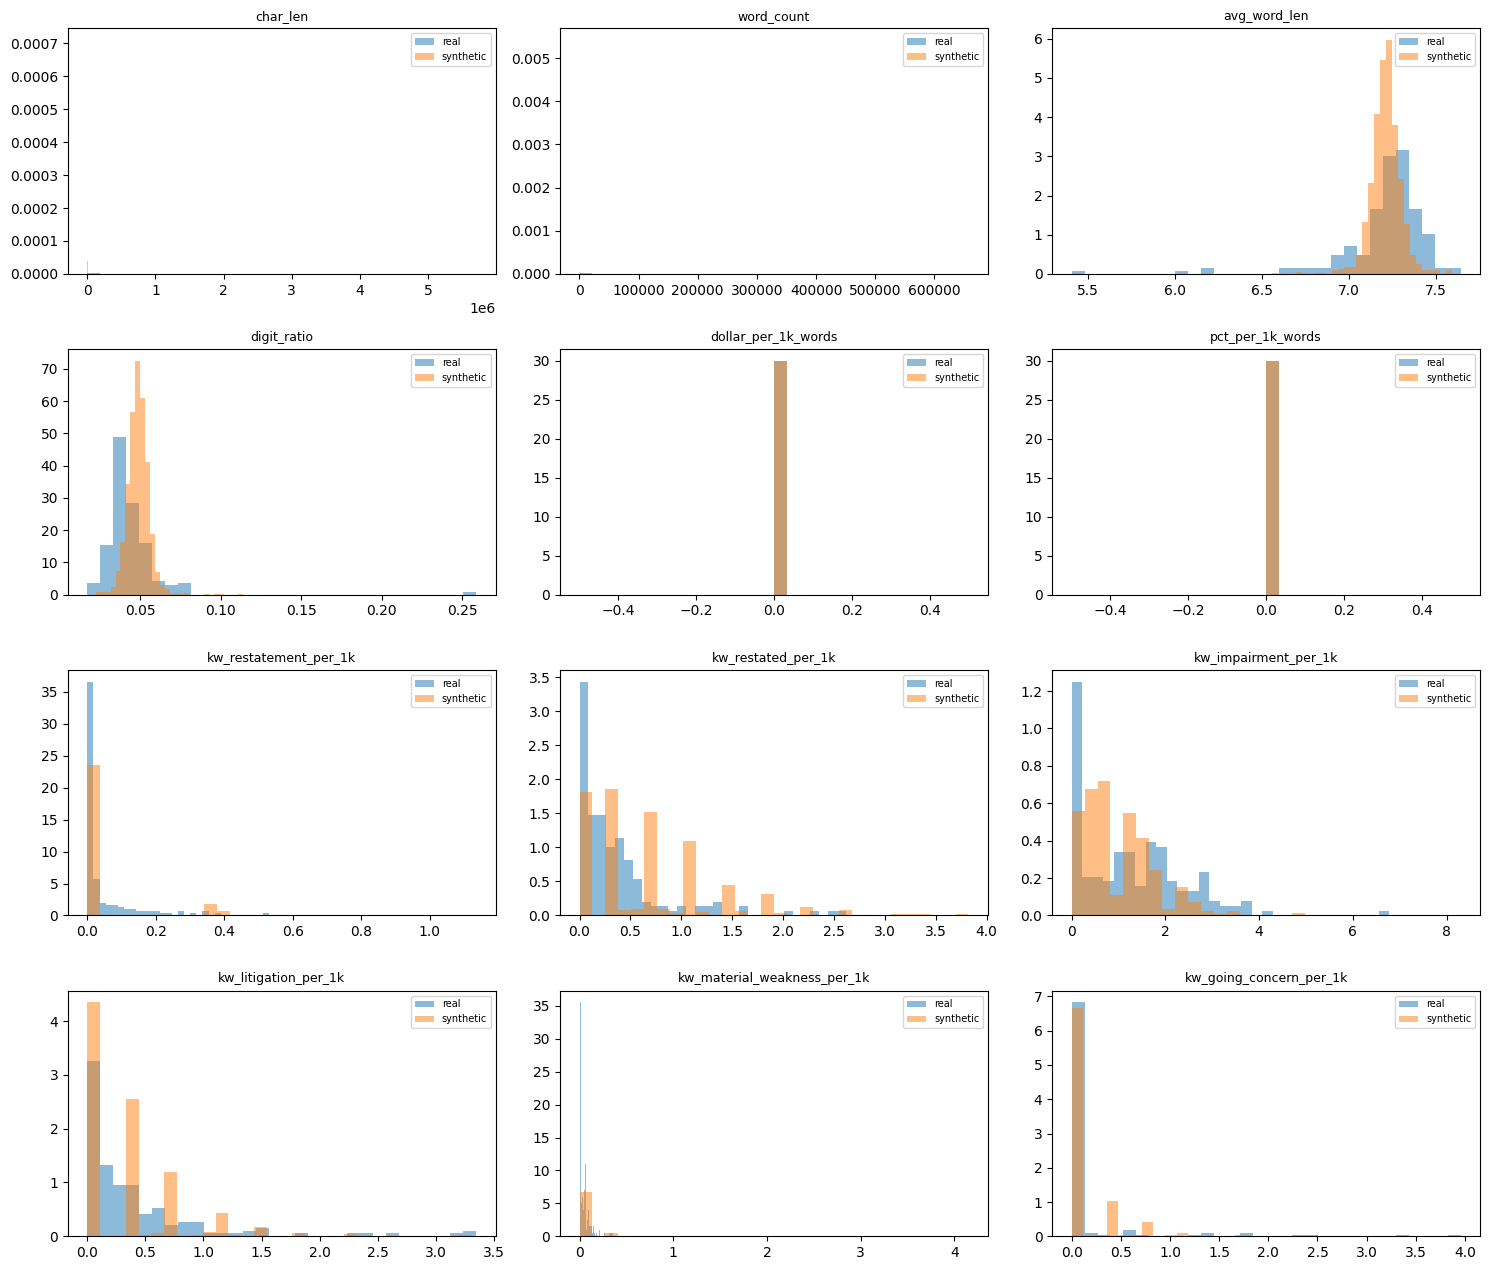

In [11]:
# Validation Histograms

plot_cols = feat_cols[:12]
fig, axes = plt.subplots(int(np.ceil(len(plot_cols) / 3)), 3, figsize=(15, 3.2 * np.ceil(len(plot_cols) / 3)))
for ax, c in zip(np.ravel(axes), plot_cols):
    ax.hist(prof_real[c].dropna(), bins=30, alpha=.5, density=True, label="real")
    ax.hist(prof_syn[c].dropna(), bins=30, alpha=.5, density=True, label="synthetic")
    ax.set_title(c.split("__")[-1], fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [12]:
# Validation: Check Constraints
checks = {}
for tc in TEXT_COLS:
    checks[f"{tc}: word_count > 0"] = (prof_syn[f"{tc}__word_count"] > 0)[df_syn[tc].notna()].all()
    checks[f"{tc}: no exact copies of real rows"] = not df_syn[tc].dropna().isin(set(df_real[tc].dropna())).any()
for c in CAT_COLS:
    checks[f"{c}: only real categories"] = set(df_syn[c].dropna()) <= set(df_real[c].dropna())
for c in NUM_COLS:
    checks[f"{c}: within real [min, max]"] = df_syn[c].dropna().between(df_real[c].min(), df_real[c].max()).all()
    if (df_real[c].dropna() >= 0).all():
        checks[f"{c}: >= 0"] = (df_syn[c].dropna() >= 0).all()
for c in df_real.columns:
    checks[f"{c}: null rate within 5 pts"] = abs(df_syn[c].isna().mean() - df_real[c].isna().mean()) <= .05
display(pd.Series(checks, name="passed").to_frame())

,passed
Fillings: word_count > 0,True
Fillings: no exact copies of real rows,True
Fraud: only real categories,True
Fillings: null rate within 5 pts,True
Fraud: null rate within 5 pts,True


In [13]:
# Validation: privacy check (copied 8-word phrases)

def ngrams(s, n=8):
    t = tokenize(s); return {tuple(t[i:i+n]) for i in range(len(t) - n + 1)}

for tc in TEXT_COLS:
    real_ng = set().union(*[ngrams(s) for s in df_real[tc].dropna().map(lambda s: " ".join(tokenize(s)[:TRAIN_TOKENS_PER_DOC]))])
    overlap = [len(ngrams(s) & real_ng) / max(len(ngrams(s)), 1) for s in df_syn[tc].dropna().sample(min(100, df_syn[tc].notna().sum()), random_state=SEED)]
    print(f"{tc}: share of synthetic 8-word phrases copied from real text = {np.mean(overlap):.1%}")

Fillings: share of synthetic 8-word phrases copied from real text = 11.0%


In [14]:
# Validation (TSTR)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score

if TEXT_COLS and LABEL_COL:
    tc = TEXT_COLS[0]
    r = df_real.dropna(subset=[tc, LABEL_COL]); s = df_syn.dropna(subset=[tc, LABEL_COL])
    pos = sorted(r[LABEL_COL].unique())[-1]           # treat the "higher" label (e.g. 'yes'/1) as positive
    yr, ys = (r[LABEL_COL] == pos).astype(int), (s[LABEL_COL] == pos).astype(int)
    mk = lambda: make_pipeline(TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True),
                               LogisticRegression(max_iter=2000))
    trtr = cross_val_score(mk(), r[tc], yr, cv=5, scoring="roc_auc").mean()
    m = mk().fit(s[tc], ys); p = m.predict_proba(r[tc])[:, 1]
    print(f"Train on real, test on real (5-fold CV) AUC: {trtr:.3f}")
    print(f"Train on synthetic, test on real AUC: {roc_auc_score(yr, p):.3f} | Acc: {accuracy_score(yr, p > .5):.3f}")


Train on real, test on real (5-fold CV) AUC: 0.930
Train on synthetic, test on real AUC: 0.981 | Acc: 0.924


In [15]:
df_syn.to_csv("synthetic_financial_fraud.csv", index=False)
print("Saved", df_syn.shape)

Saved (1000, 2)


In [16]:
import os
print(os.getcwd())
print(os.listdir())

/opt/app-root/src/Shaam
['.ipynb_checkpoints', 'synthetic_financial_fraud.csv', 'Synthetic Data Generator']


In [20]:
from pathlib import Path
print(Path.cwd())

/opt/app-root/src/Shaam
